## Testing in silico treatment population response

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import sobol_seq
import math
from pathlib import Path
import os

In [2]:
SAVEFILES = True
OVERWRITE = True

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)

#### Import model version with inhibitor rules (saved in Python/test_treatments)

In [3]:
##Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count
# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model


##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator

In [4]:
sys.path.insert(0, "./../cellular_cycle") 
from model_fxns import *

In [6]:
# t = np.linspace(0, 10000, 100001)
t = np.linspace(0, 20000, 200001)
# t = np.linspace(0, 50000, 500001)

model.parameters['AKT'].value = 0.3
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 0.4

In [7]:
# Importing the parameters:
new_param = pd.read_csv('parameters_cycdi.csv')
del new_param['Stress']
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
F_n.1
K_p21fak.1
k_CDF
K_DF
K_dcescp2


<Axes: xlabel='Time (h)', ylabel='Concentration'>

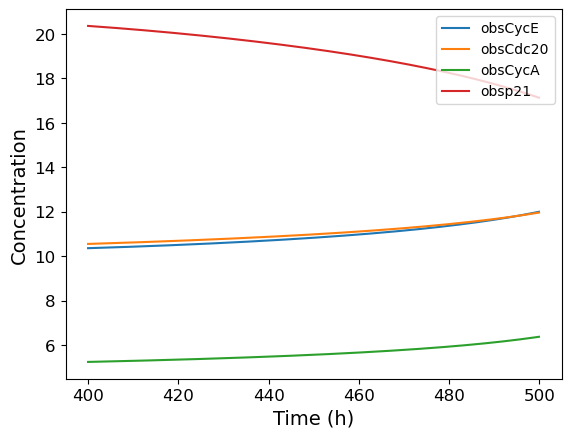

In [8]:
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run(); #deterministic simulation

### Define observables to plot (will be reused)

observables=['obsCycE','obsCdc20', 'obsCycA', 'obsp21']; #plot Cyclin E, Cdc20 and Cyclin A

### Plot ODE simulation output of new model file


plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(4000,5000), legend=True)


<Axes: xlabel='Time (h)', ylabel='Concentration'>

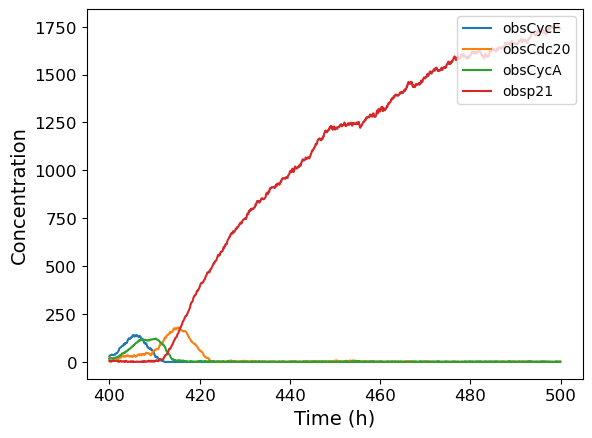

In [9]:
### Simulate model with stochastic simulator

sim_stoch = BngSimulator(model, tspan=t, verbose=False);
sim_stoch_res = sim_stoch.run(method='ssa', verbose=False, seed=33); 


plotObs(model=sim_stoch_res.all, obs=observables, times=t, tpos=range(4000,5000), legend=True)

In [10]:
omega = 200
ecm_conditions = pd.read_csv('ECM_conditions.csv', index_col=[0])
ecm_conditions

FileNotFoundError: [Errno 2] No such file or directory: 'ECM_conditions.csv'

In [5]:
#Plotting parameters
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

#### Testing model output

2023-01-16 17:07:58.667 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


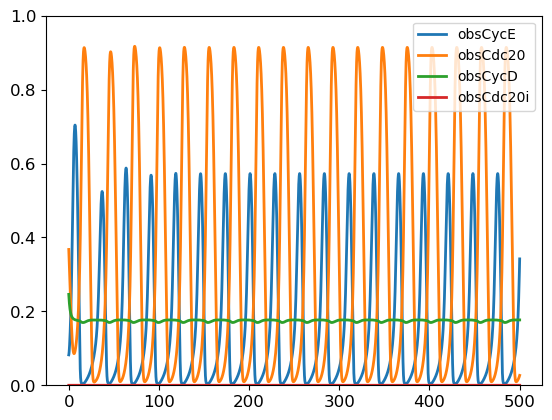

In [4]:
omega = 200
new_param = pd.read_csv("parameters.csv") 
del new_param['Stress']
for key in new_param.keys():
    if model_population.parameters[key].value != new_param[key][0]:
        model_population.parameters[key].value = int(round(new_param[key]* 200))
    if model_concentration.parameters[key].value != new_param[key][0]:
        model_concentration.parameters[key].value = new_param[key]
model_concentration.parameters['omega'].value = 1

model_population.parameters['ERK'].value = 0.2 * omega
model_population.parameters['FAK'].value = 1.0 * omega
model_population.parameters['AKT'].value = 0.6 * omega

model_concentration.parameters['ERK'].value = 0.2 * 1
model_concentration.parameters['FAK'].value = 1 * 1
model_concentration.parameters['AKT'].value = 0.6 * 1
t = np.linspace(0, 500, 50000)
simres = ScipyOdeSimulator(model_concentration, t, verbose=False).run()
yout = simres.all;
observables=['obsCycE', 'obsCdc20', 'obsCycD', 'obsCdc20i']; #plot Cyclin E, Cdc20 and Cyclin A
for obs in range(4) :
    plt.plot(t[:],yout[observables[obs]][:], label=observables[obs], lw=2)
plt.legend(loc=1)
plt.ylim(0, 1)
plt.show()

#### CyclinD/Cdk4-6 inhibition

2023-01-17 01:00:14.781 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


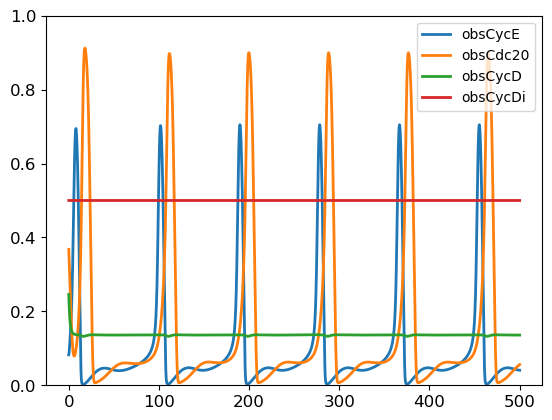

In [95]:
#change the model parameters of the model if needed
omega = 200
new_param = pd.read_csv("parameters_cycdi.csv") 
del new_param['Stress']
for key in new_param.keys():
    if model_population.parameters[key].value != new_param[key][0]:
        model_population.parameters[key].value = new_param[key]
    if model_concentration.parameters[key].value != new_param[key][0]:
        model_concentration.parameters[key].value = new_param[key]
model_concentration.parameters['omega'].value = 1
model_population.parameters['ERK'].value = 0.2 * omega
model_population.parameters['FAK'].value = 1.0 * omega
model_population.parameters['AKT'].value = 0.6 * omega

model_concentration.parameters['ERK'].value = 0.2 * 1
model_concentration.parameters['FAK'].value = 1 * 1
model_concentration.parameters['AKT'].value = 0.6 * 1
t = np.linspace(0, 500, 50000)
simres = ScipyOdeSimulator(model_concentration, t, verbose=False).run()
yout = simres.all;
observables=['obsCycE', 'obsCdc20', 'obsCycD', 'obsCycDi']; #plot Cyclin E, Cdc20 and Cyclin A
for obs in range(4) :
    plt.plot(t[:],yout[observables[obs]][:], label=observables[obs], lw=2)
plt.legend(loc=1)
plt.ylim(0, 1)
plt.show()

In [6]:
sys.path.insert(0, os.getcwd() + "/../cellular_cycle") #add a pathway to the model #not sure about how to use folder dependency, to change
sys.path.insert(0, os.getcwd() + "/../fit")

In [7]:
from runAKTERK_2 import runAKTERK #Simulate a population of cells from independants biochemical models
from runStochCell import runStochcell
import fracprolif as fp
from rbf_mmd import nmmd2_rbf

In [8]:
run_time=120 #how long is the experiment
observed_cells_time=120 #how long are we looking at new cells
nber_of_starting_cells=10 #size of initial population
index="_" #to be removed...
condition="_" #to be removed...

In [9]:
(cells, cell_count) = runAKTERK(nber_of_starting_cells, run_time, observed_cells_time, model_concentration, model_population, index, condition);


2023-01-16 17:08:35.542 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 18, 45, 71, 99, 119, 156, 182, 204, 234, 261, 286, 309, 332, 359, 376, 416, 461, 485, 509, 543, 573, 596, 628, 647, 673, 735, 765, 791, 845, 875, 901, 950, 999]


In [45]:
def run_model_DIP(nber_of_starting_cells, run_time, observed_cells_time, model_concentration, model_population, index, condition, figname):
    (cells, cell_count) = runAKTERK(nber_of_starting_cells, run_time, observed_cells_time, model_concentration, model_population, index, condition)
    log2cell = [math.log2(x/cell_count[0,1]) for x in cell_count[:,1]]
    m,b = np.polyfit(cell_count[round(len(cell_count)/2):,0], log2cell[round(len(cell_count)/2):], 1)
    
    fig, ax = plt.subplots( nrows=1, ncols=1 )  # create figure & 1 axis
    
    plt.ylim([0, 6])
    ax.plot(cell_count[:,0], log2cell)
    fig.savefig(figname)
    
    return m

2023-01-17 01:56:40.910 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 16, 43, 66, 101, 132, 158, 184, 207, 239, 259, 293, 310, 331, 375, 425, 465, 493, 522, 545, 573, 608, 634, 665, 685, 720, 744, 767, 788, 810, 837, 858, 888, 913, 939, 959, 986]


2023-01-17 02:01:31.283 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 18, 46, 73, 98, 127, 152, 204, 229, 261, 304, 338, 362, 392, 408, 430, 454, 507, 534, 565, 589, 611, 642, 665, 694, 720, 745, 770, 800, 826, 852, 886, 905, 930, 963, 999]


2023-01-17 02:03:45.584 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


...

False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 16, 42, 69, 91, 124, 146, 187, 209, 246, 271, 291, 349, 373, 400, 423, 450, 473, 496, 545, 591, 639, 663, 695, 722, 741, 766, 791, 810, 832, 861, 891, 912, 941, 959, 988]


2023-01-17 02:18:30.712 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 19, 79, 104, 130, 165, 186, 216, 231, 282, 305, 347, 384, 407, 441, 465, 493, 514, 555, 578, 599, 627, 691, 721, 746, 771, 804, 829, 877, 940, 966]


2023-01-17 02:20:12.101 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 15, 49, 74, 139, 171, 189, 213, 256, 281, 301, 327, 350, 407, 441, 455, 482, 506, 539, 574, 601, 638, 661, 703, 730, 758, 780, 804, 854, 874, 910, 928, 957, 984]


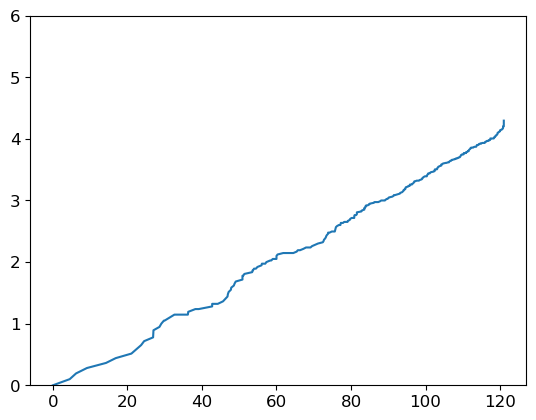

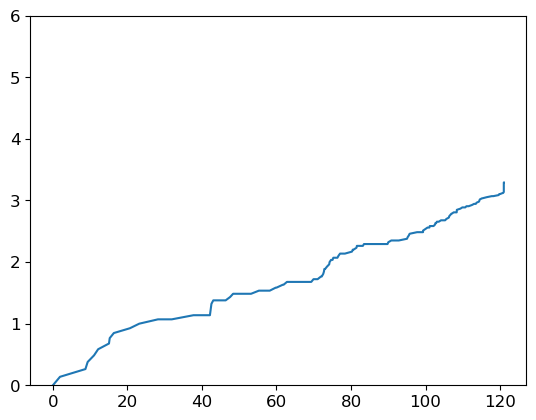

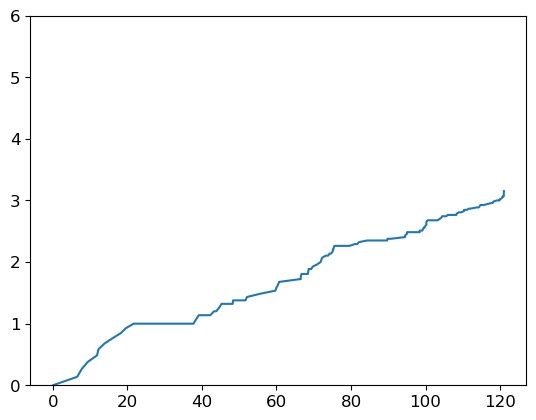

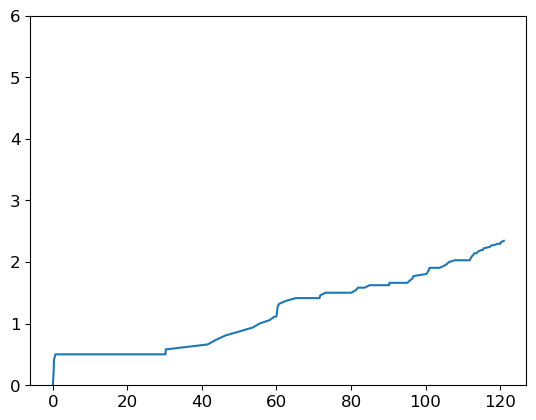

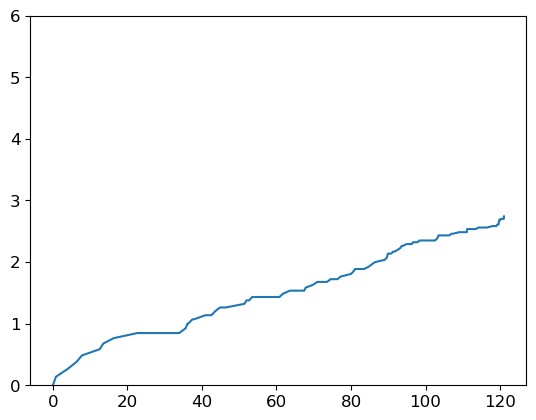

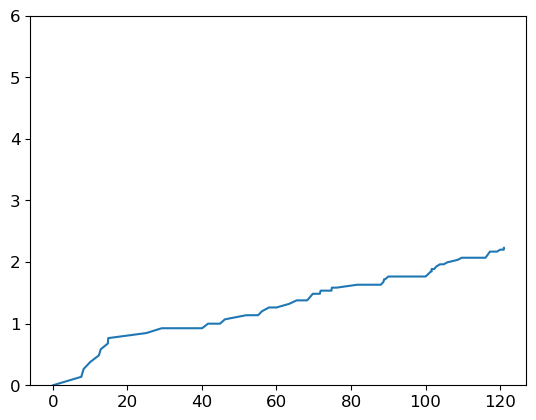

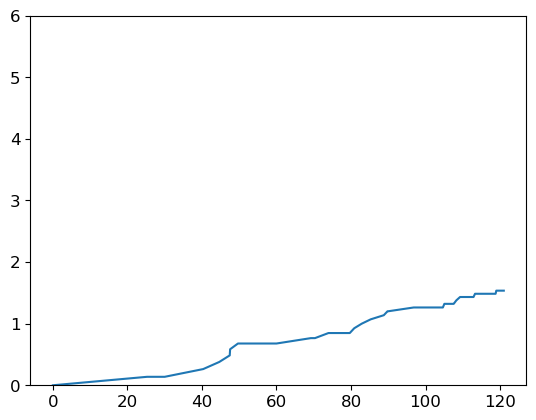

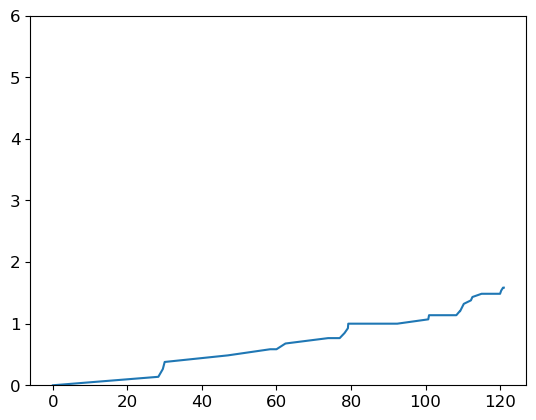

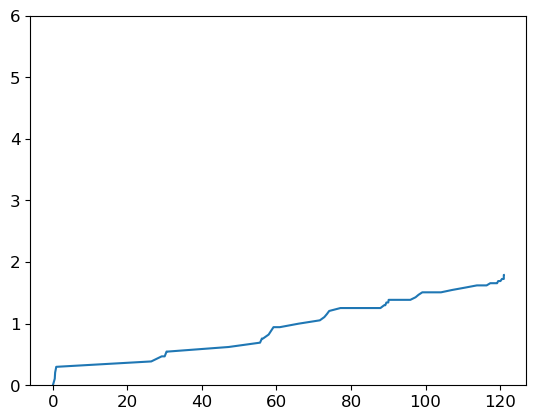

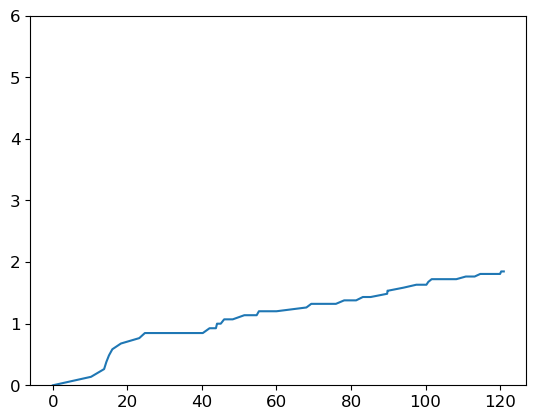

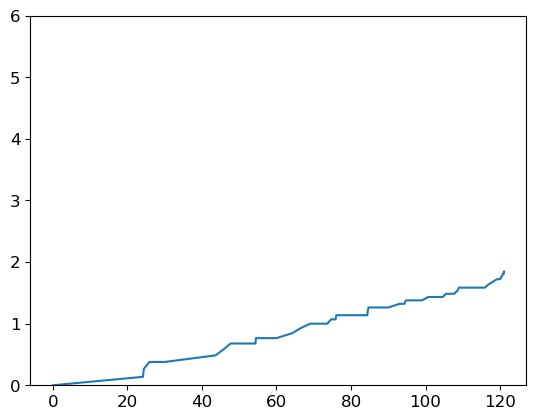

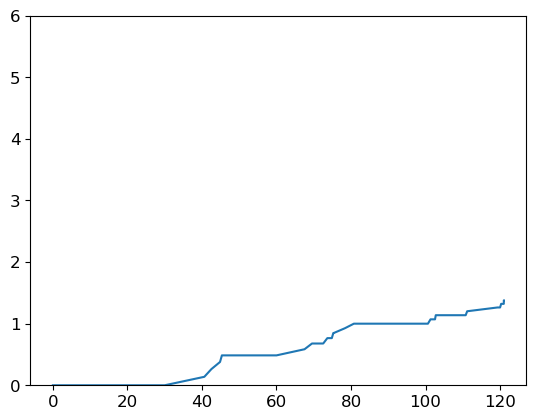

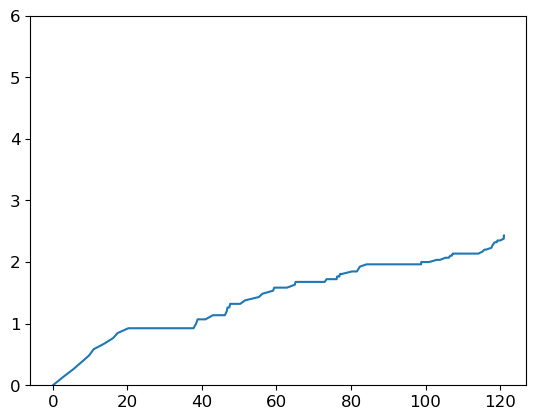

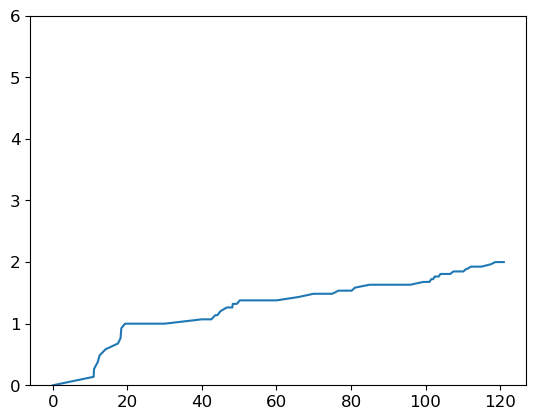

In [108]:
conc = list(np.linspace(0,1.3,num=14))
conc = [round(x,1) for x in conc]
drug = 'cycD'
cycD_DIP = []
ii=0

for num in conc:
    figname = f"C:\\Users\\olesk\\ECM_mod_output\\{drug}_{str(ii)}.svg"
    model_population.parameters['CycDi_0'].value = num
    model_concentration.parameters['CycDi_0'].value = num
    tmp_m = run_model_DIP(nber_of_starting_cells, run_time, observed_cells_time, model_concentration, model_population, index, condition, figname)
    cycD_DIP.append(tmp_m)
    ii+=1

In [107]:
model_population.parameters['CycDi_0'].value

2.0

2023-01-17 09:16:06.612 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[1, 19, 47, 74, 92, 123, 154, 185, 214, 239, 267, 298, 316, 354, 377, 405, 444, 471, 496, 523, 548, 569, 594, 622, 642, 668, 696, 718, 767, 794, 826, 852, 880, 906, 973, 999]


2023-01-17 09:20:48.995 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 17, 62, 88, 113, 151, 179, 201, 238, 265, 316, 338, 371, 391, 421, 454, 485, 519, 569, 591, 614, 637, 669, 694, 753, 789, 817, 858, 883, 921, 941, 974, 997]


2023-01-17 09:24:20.720 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


...

False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[17, 41, 65, 92, 117, 141, 167, 198, 220, 253, 292, 315, 341, 371, 394, 423, 459, 484, 510, 537, 564, 598, 619, 644, 691, 718, 756, 775, 801, 820, 840, 866, 897, 921, 950, 966, 989]


2023-01-17 09:56:09.872 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 19, 39, 69, 94, 117, 148, 165, 198, 223, 247, 278, 301, 324, 377, 418, 438, 471, 497, 525, 545, 573, 591, 630, 657, 683, 713, 738, 768, 793, 821, 843, 873, 898, 918, 948, 971, 993]


2023-01-17 09:57:58.849 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 21, 49, 85, 113, 141, 167, 200, 226, 251, 301, 331, 348, 378, 402, 428, 452, 487, 518, 546, 573, 614, 639, 669, 696, 732, 767, 792, 822, 851, 869, 923, 963, 987]


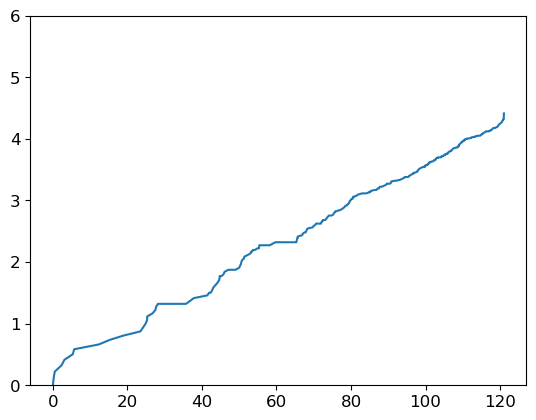

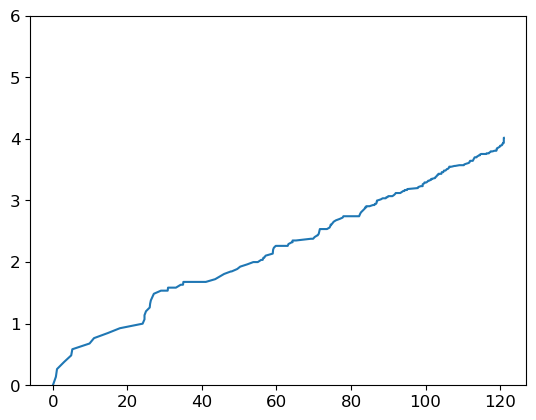

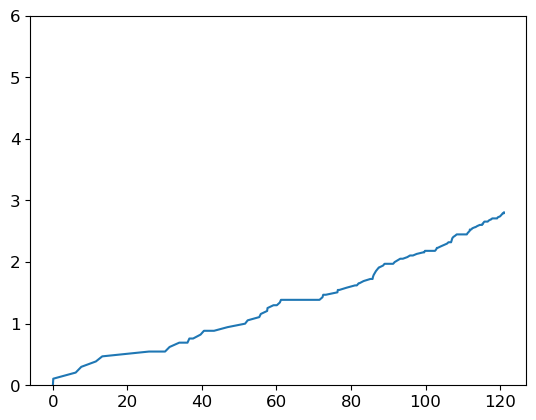

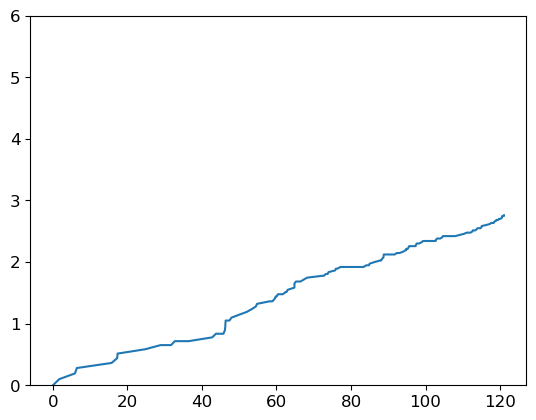

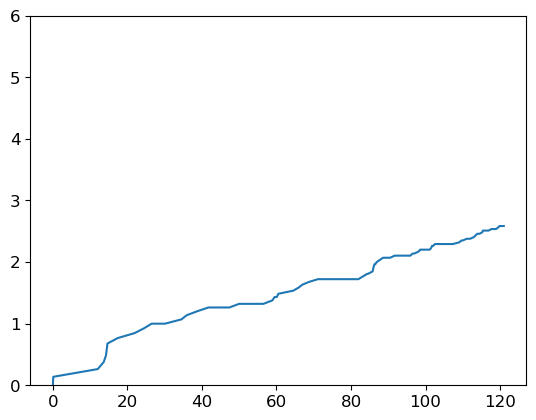

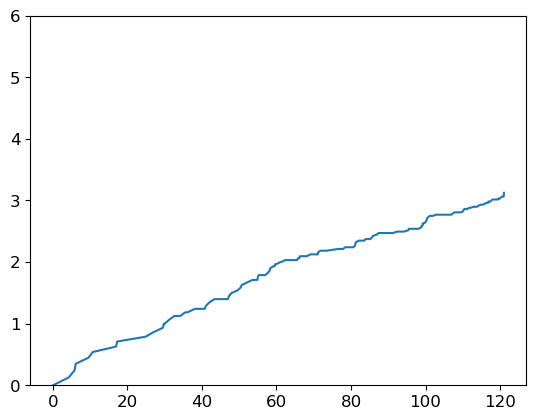

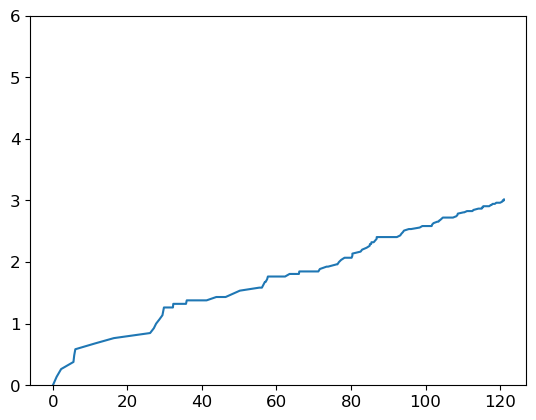

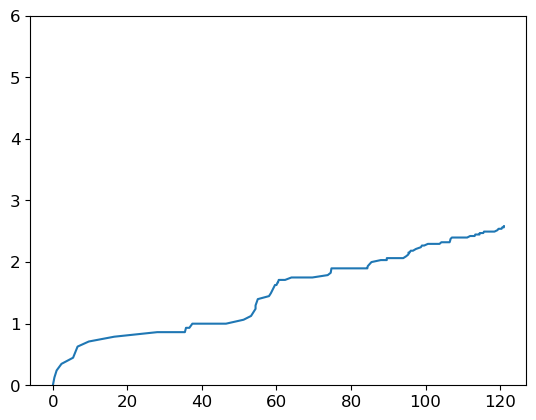

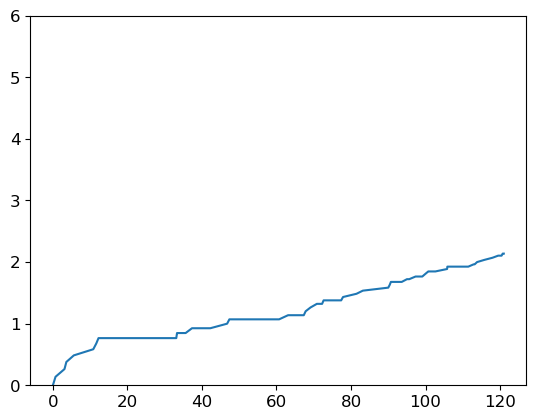

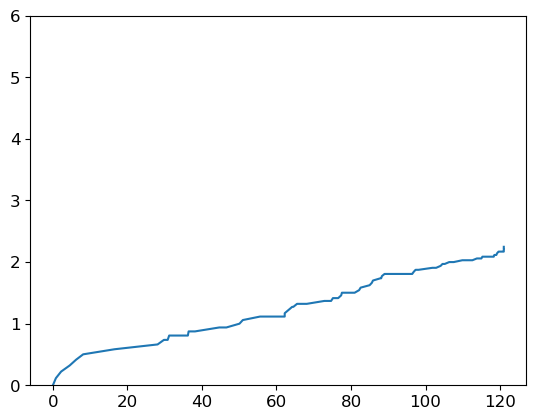

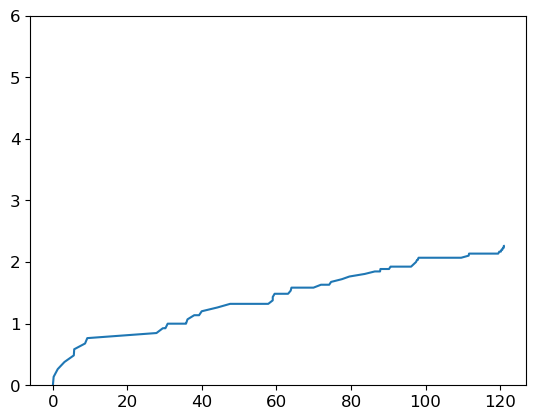

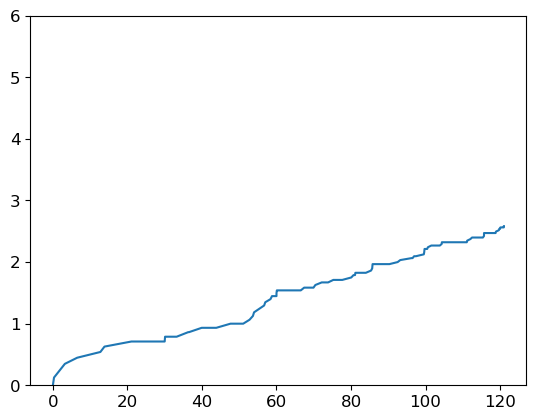

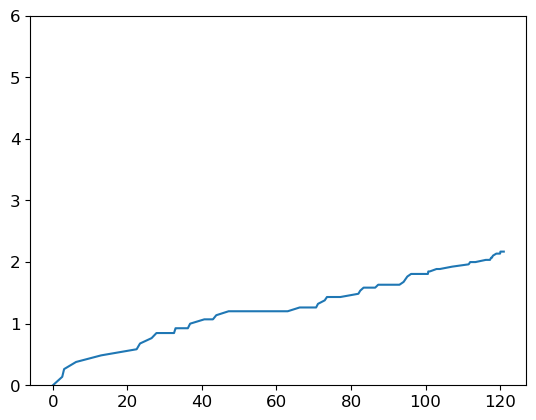

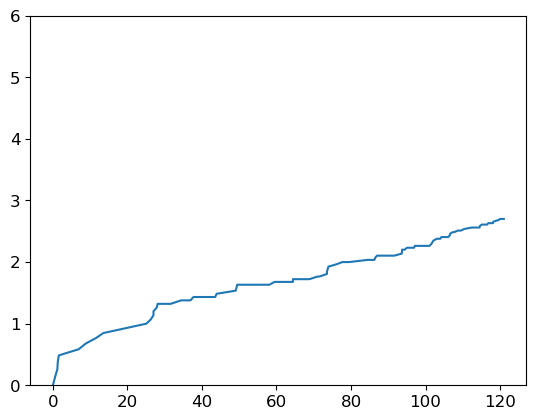

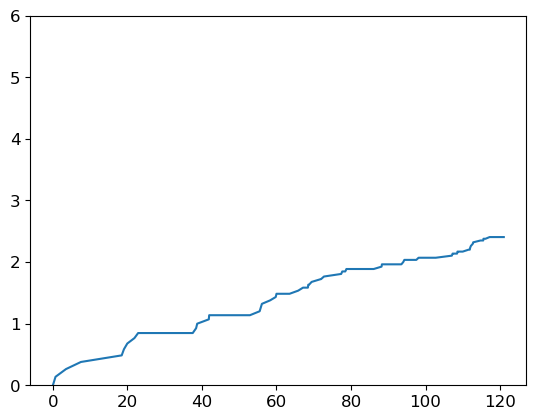

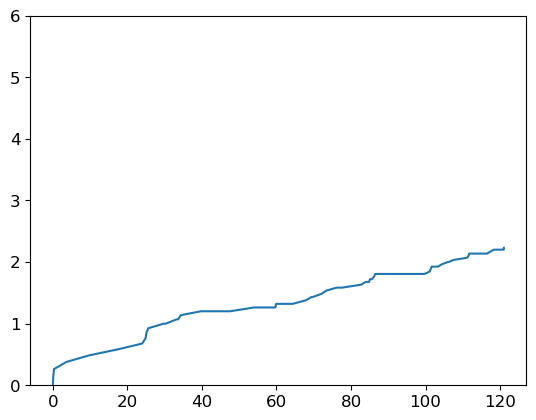

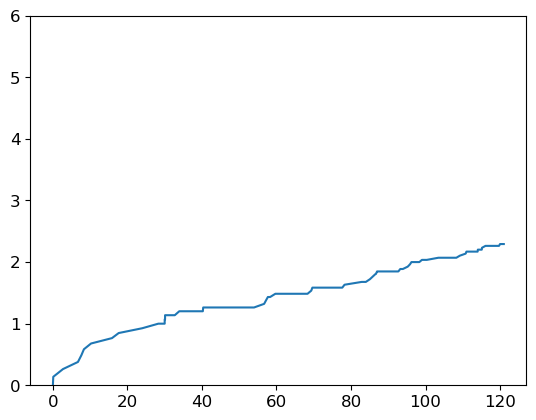

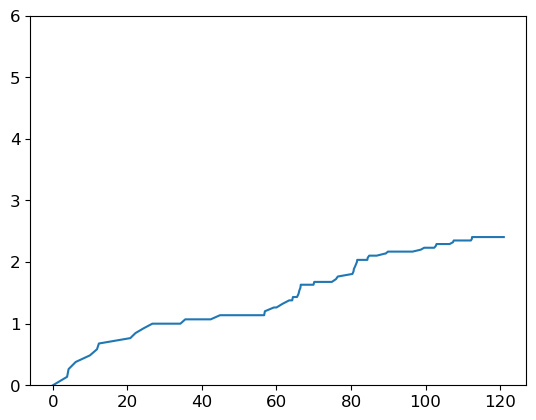

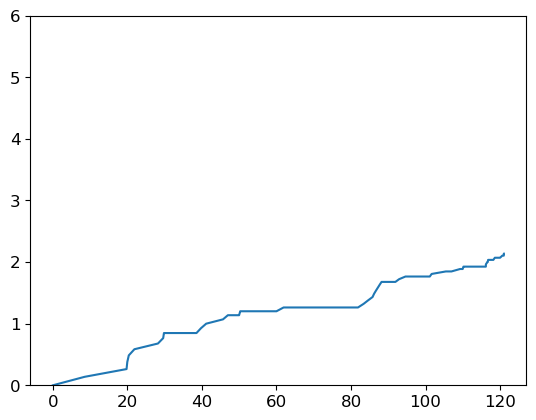

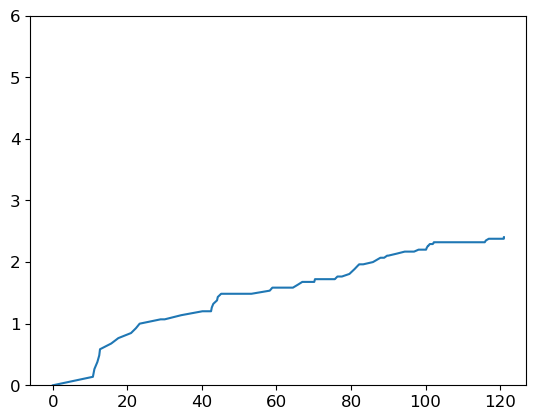

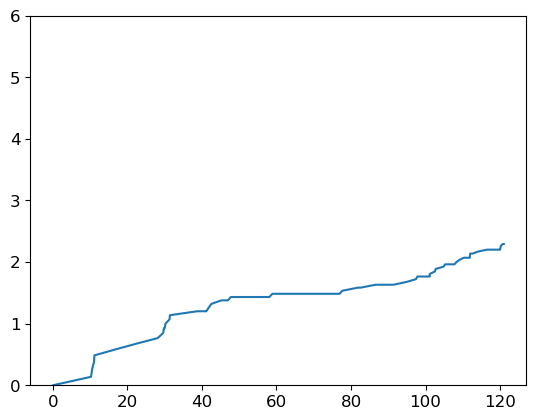

In [127]:
omega = 200
new_param = pd.read_csv("parameters.csv") 
del new_param['Stress']
for key in new_param.keys():
    if model_population.parameters[key].value != new_param[key][0]:
        model_population.parameters[key].value = int(round(new_param[key]* 200))
    if model_concentration.parameters[key].value != new_param[key][0]:
        model_concentration.parameters[key].value = new_param[key]
model_concentration.parameters['omega'].value = 1

model_population.parameters['ERK'].value = 0.2 * omega
model_population.parameters['FAK'].value = 1.0 * omega
model_population.parameters['AKT'].value = 0.6 * omega

model_concentration.parameters['ERK'].value = 0.2 * 1
model_concentration.parameters['FAK'].value = 1 * 1
model_concentration.parameters['AKT'].value = 0.6 * 1

conc = list(np.linspace(0,2,num=21))
conc = [round(x,1) for x in conc]
drug = 'E2F'
e2f_DIP = []
ii=0

for num in conc:
    figname = f"C:\\Users\\olesk\\ECM_mod_output\\{drug}_{str(ii)}.svg"
    model_population.parameters['E2Fi_0'].value = num
    model_concentration.parameters['E2Fi_0'].value = num
    tmp_m = run_model_DIP(nber_of_starting_cells, run_time, observed_cells_time, model_concentration, model_population, index, condition, figname)
    e2f_DIP.append(tmp_m)
    ii+=1

2023-01-17 09:59:36.136 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 17, 62, 87, 115, 143, 173, 196, 221, 249, 296, 318, 346, 372, 406, 435, 464, 491, 518, 560, 605, 635, 676, 722, 758, 777, 805, 826, 846, 872, 904, 929, 951, 974]


2023-01-17 10:04:46.974 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 20, 45, 78, 110, 137, 174, 205, 230, 277, 319, 357, 427, 461, 496, 528, 554, 612, 685, 715, 744, 780, 798, 823, 850, 878, 926, 949, 971, 999]


2023-01-17 10:09:23.146 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


...

2023-01-17 10:17:07.826 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 19, 119, 213, 273, 438, 498, 527, 574, 595, 653, 897, 932, 962]


2023-01-17 10:18:24.404 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 31, 128, 196, 334, 360, 429, 624, 802, 849]


TypeError: 'int' object is not subscriptable

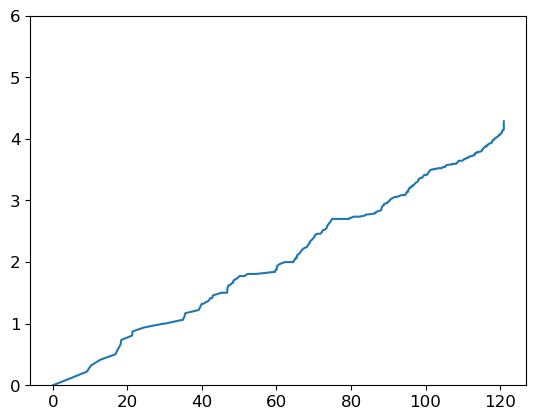

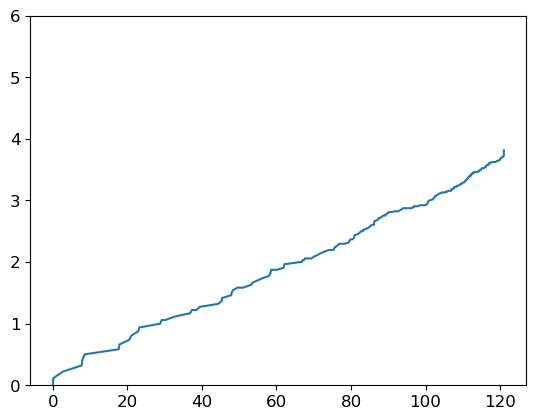

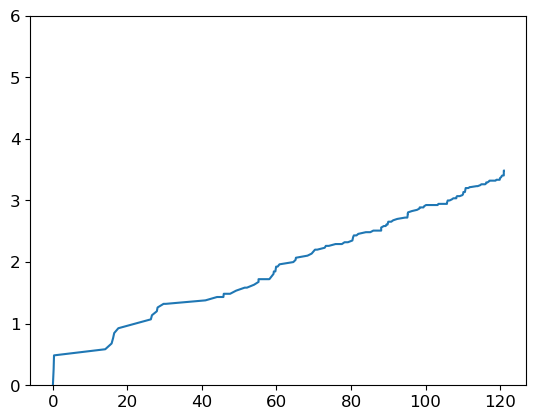

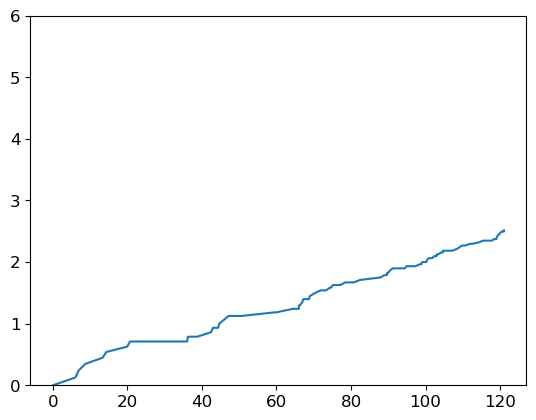

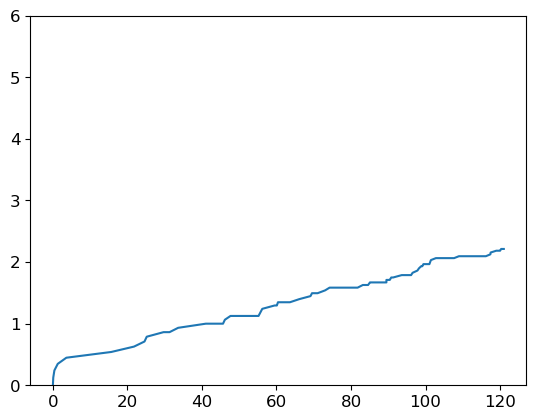

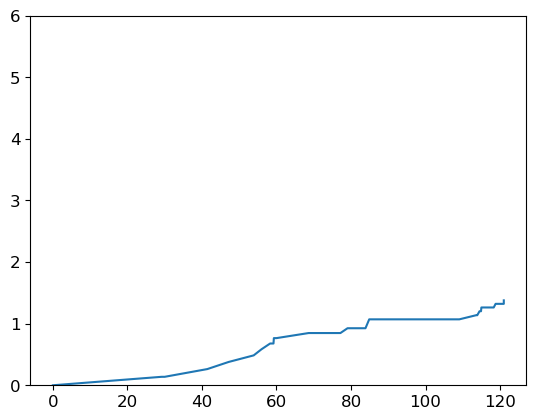

In [128]:
omega = 200
new_param = pd.read_csv("parameters.csv") 
del new_param['Stress']
for key in new_param.keys():
    if model_population.parameters[key].value != new_param[key][0]:
        model_population.parameters[key].value = int(round(new_param[key]* 200))
    if model_concentration.parameters[key].value != new_param[key][0]:
        model_concentration.parameters[key].value = new_param[key]
model_concentration.parameters['omega'].value = 1

model_population.parameters['ERK'].value = 0.2 * omega
model_population.parameters['FAK'].value = 1.0 * omega
model_population.parameters['AKT'].value = 0.6 * omega

model_concentration.parameters['ERK'].value = 0.2 * 1
model_concentration.parameters['FAK'].value = 1 * 1
model_concentration.parameters['AKT'].value = 0.6 * 1

conc = list(np.linspace(0,18,num=19))
conc = [round(x,1) for x in conc]
conc.reverse()
drug = 'rbD'
rbD_DIP = []
ii=0

for num in conc:
    figname = f"C:\\Users\\olesk\\ECM_mod_output\\{drug}_{str(ii)}.svg"
    model_population.parameters['k_P1'].value = num
    model_concentration.parameters['k_P1'].value = num
    tmp_m = run_model_DIP(nber_of_starting_cells, run_time, observed_cells_time, model_concentration, model_population, index, condition, figname)
    rbD_DIP.append(tmp_m)
    ii+=1

2023-01-17 10:31:48.431 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.
Exception ignored in: <function RhsBuilder.__del__ at 0x000001E11DB5A5E0>
Traceback (most recent call last):
  File "C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\pysb\simulator\scipyode.py", line 470, in __del__
    if self._work_path:
AttributeError: 'PythonRhsBuilder' object has no attribute '_work_path'


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[15, 41, 63, 85, 107, 130, 155, 176, 197, 220, 244, 265, 288, 313, 340, 365, 386, 409, 433, 457, 479, 502, 526, 548, 573, 598, 622, 646, 669, 690, 717, 737, 762, 789, 809, 834, 858, 881, 906, 930, 955, 975, 999]


2023-01-17 10:41:01.849 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[14, 38, 62, 86, 109, 133, 155, 178, 202, 224, 251, 272, 293, 319, 344, 363, 385, 410, 432, 455, 479, 503, 528, 551, 572, 597, 618, 640, 661, 682, 708, 730, 750, 776, 799, 824, 843, 870, 895, 918, 939, 966, 991]


2023-01-17 10:51:18.300 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


...

2023-01-17 11:11:38.189 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 15, 42, 64, 85, 107, 126, 148, 173, 192, 218, 241, 265, 289, 312, 338, 359, 383, 406, 430, 454, 478, 502, 522, 548, 571, 593, 613, 638, 658, 686, 707, 728, 753, 779, 800, 827, 850, 871, 895, 918, 944, 968, 992]


2023-01-17 11:23:58.726 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 15, 40, 63, 85, 107, 129, 155, 176, 202, 225, 248, 272, 295, 317, 336, 364, 385, 411, 437, 460, 488, 510, 532, 552, 575, 601, 623, 646, 669, 694, 717, 735, 760, 785, 807, 828, 851, 873, 898, 923, 944, 970, 990]


KeyboardInterrupt: 

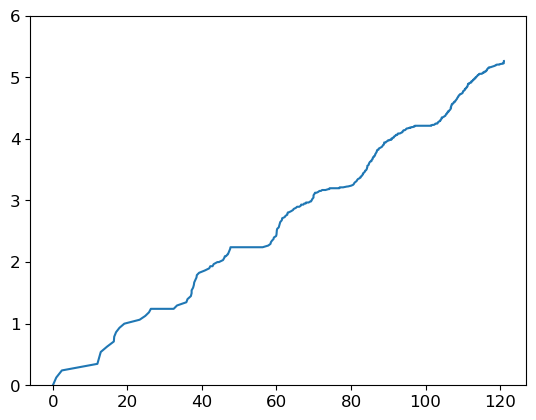

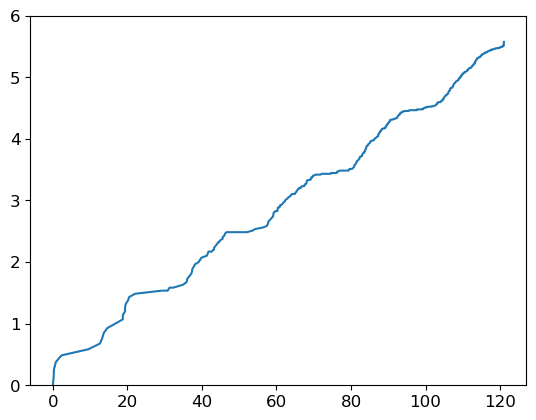

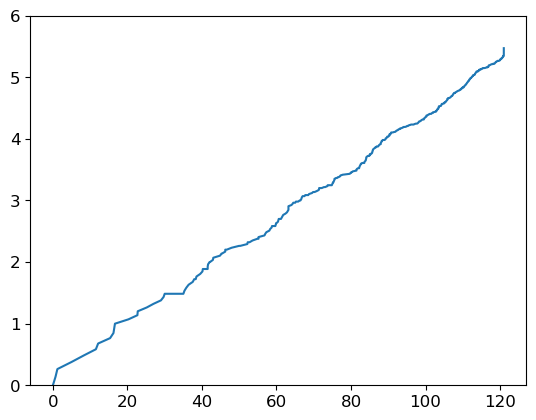

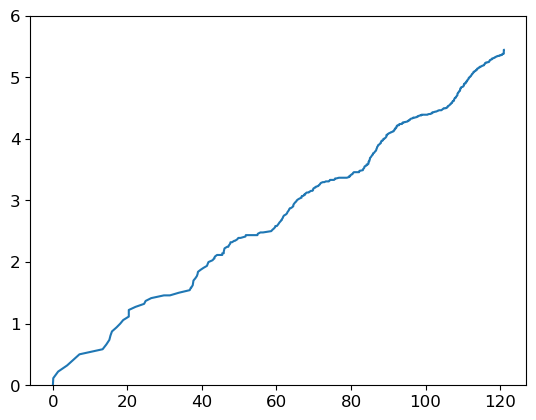

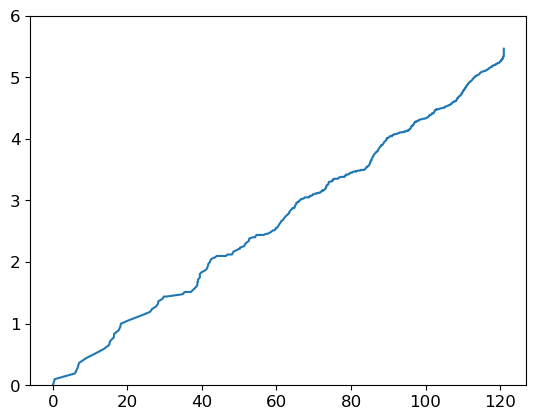

In [129]:
omega = 200
new_param = pd.read_csv("parameters.csv") 
del new_param['Stress']
for key in new_param.keys():
    if model_population.parameters[key].value != new_param[key][0]:
        model_population.parameters[key].value = int(round(new_param[key]* 200))
    if model_concentration.parameters[key].value != new_param[key][0]:
        model_concentration.parameters[key].value = new_param[key]
model_concentration.parameters['omega'].value = 1

model_population.parameters['ERK'].value = 0.2 * omega
model_population.parameters['FAK'].value = 1.0 * omega
model_population.parameters['AKT'].value = 0.6 * omega

model_concentration.parameters['ERK'].value = 0.2 * 1
model_concentration.parameters['FAK'].value = 1 * 1
model_concentration.parameters['AKT'].value = 0.6 * 1

conc = list(np.linspace(0,18,num=19))
conc = [round(x,1) for x in conc]
conc.reverse()
drug = 'rbE'
rbE_DIP = []
ii=0

for num in conc:
    figname = f"C:\\Users\\olesk\\ECM_mod_output\\{drug}_{str(ii)}.svg"
    model_population.parameters['k_P2'].value = num
    model_concentration.parameters['k_P2'].value = num
    tmp_m = run_model_DIP(nber_of_starting_cells, run_time, observed_cells_time, model_concentration, model_population, index, condition, figname)
    rbE_DIP.append(tmp_m)
    ii+=1

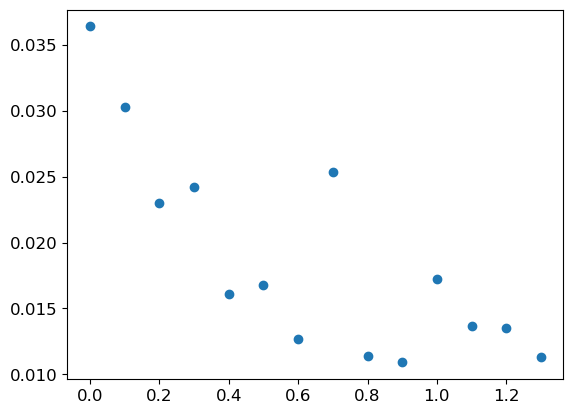

In [131]:
conc = list(np.linspace(0,1.3,num=14))
conc = [round(x,1) for x in conc]
plt.scatter(conc,cycD_DIP)

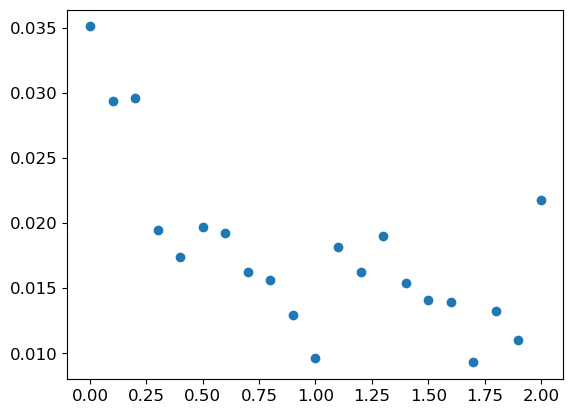

In [133]:
conc = list(np.linspace(0,2,num=21))
conc = [round(x,1) for x in conc]
plt.scatter(conc,e2f_DIP)

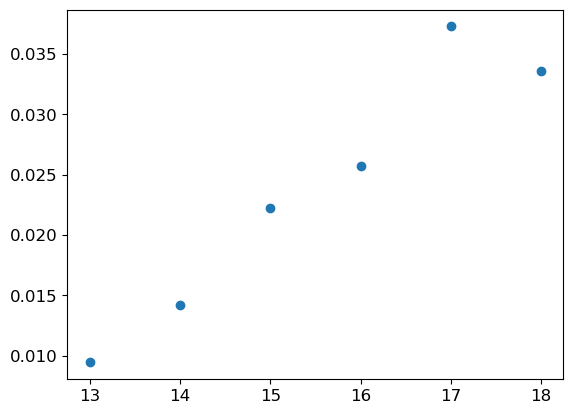

In [134]:
conc = list(np.linspace(13,18,num=6))
conc = [round(x,1) for x in conc]
conc.reverse()
plt.scatter(conc,rbD_DIP)

2023-01-17 11:51:40.054 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 16, 39, 66, 87, 110, 133, 156, 179, 205, 227, 249, 273, 293, 319, 341, 366, 390, 411, 435, 460, 483, 503, 526, 551, 571, 593, 616, 638, 659, 685, 711, 732, 758, 778, 804, 828, 851, 877, 899, 921, 944, 967, 990]


2023-01-17 11:55:31.077 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[16, 41, 62, 85, 107, 129, 152, 177, 202, 227, 251, 274, 296, 318, 341, 364, 387, 411, 432, 457, 479, 500, 522, 546, 571, 596, 618, 643, 664, 688, 712, 735, 759, 781, 802, 827, 851, 875, 898, 922, 944, 969, 995]


2023-01-17 11:58:43.839 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


...

False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 18, 40, 61, 86, 108, 128, 152, 178, 200, 225, 248, 270, 295, 317, 340, 361, 386, 407, 431, 456, 477, 501, 522, 544, 561, 586, 605, 629, 651, 676, 702, 726, 748, 770, 798, 819, 842, 864, 883, 910, 931, 956, 979, 999]


2023-01-17 12:20:21.352 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 15, 37, 59, 81, 107, 127, 151, 174, 193, 217, 239, 261, 286, 307, 327, 348, 372, 395, 420, 442, 464, 484, 510, 539, 562, 585, 608, 630, 651, 673, 696, 718, 741, 766, 790, 815, 838, 862, 886, 909, 933, 956, 975, 999]


2023-01-17 12:24:33.477 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
[0, 19, 37, 60, 83, 106, 128, 151, 173, 197, 221, 249, 270, 289, 313, 336, 362, 384, 408, 428, 451, 475, 495, 522, 544, 569, 595, 621, 643, 668, 690, 713, 734, 758, 781, 804, 829, 851, 877, 898, 923, 946, 968, 994]


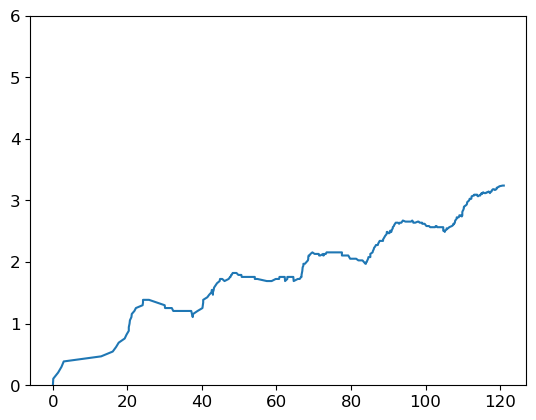

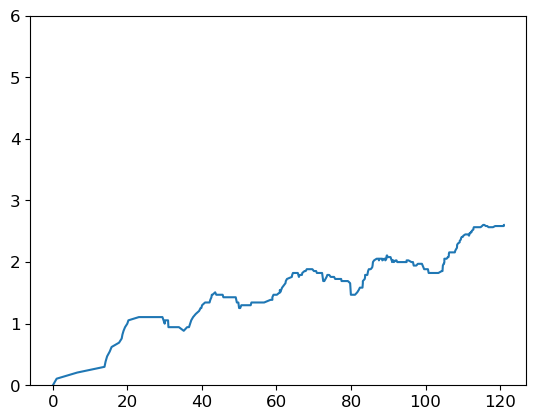

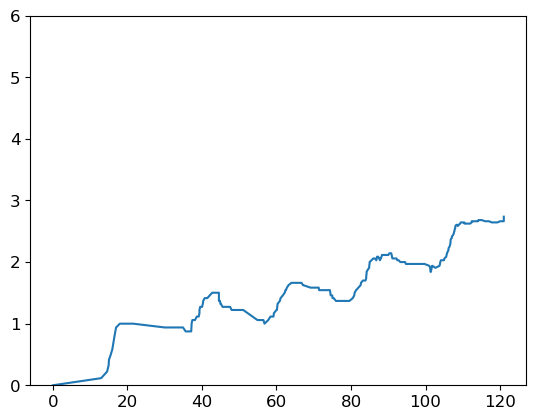

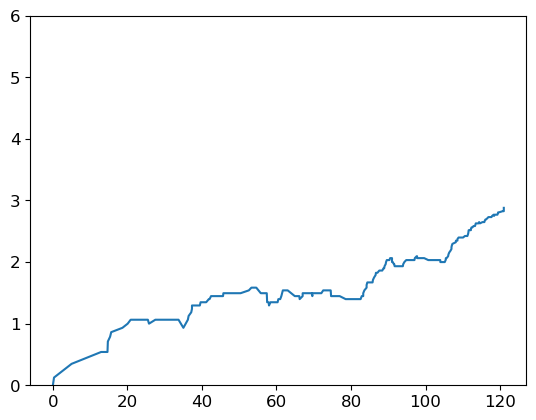

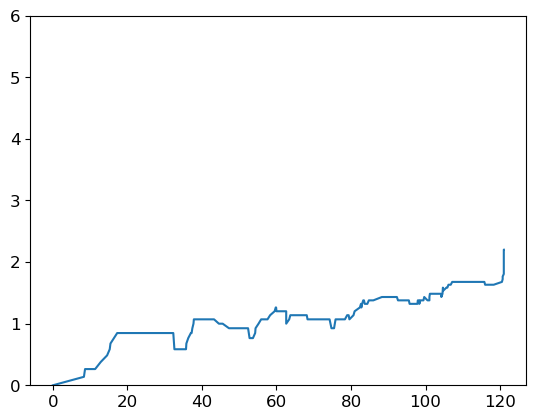

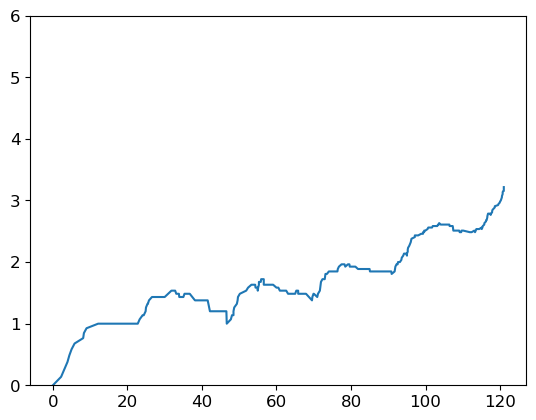

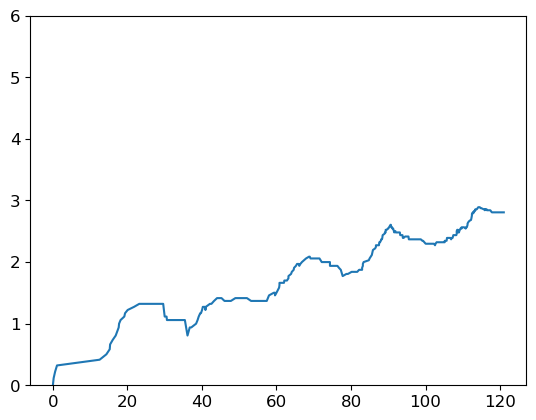

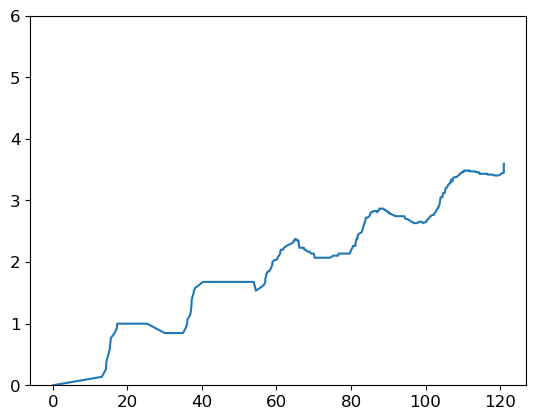

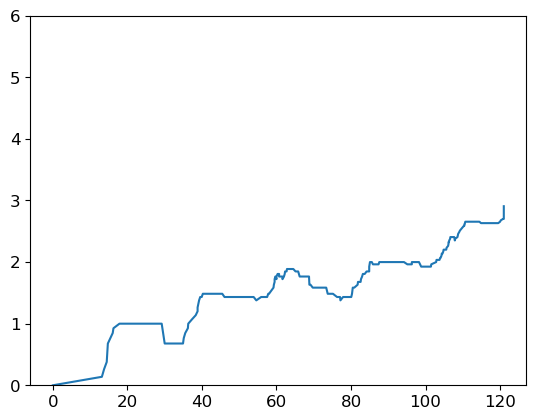

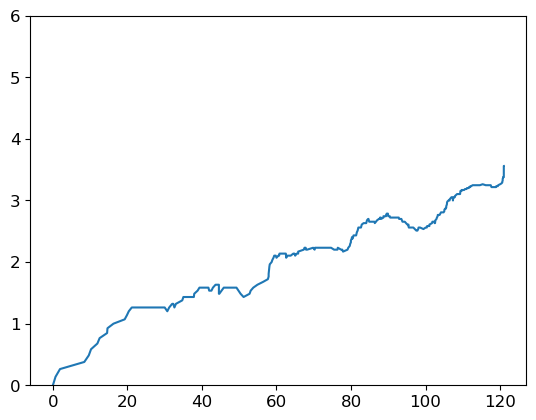

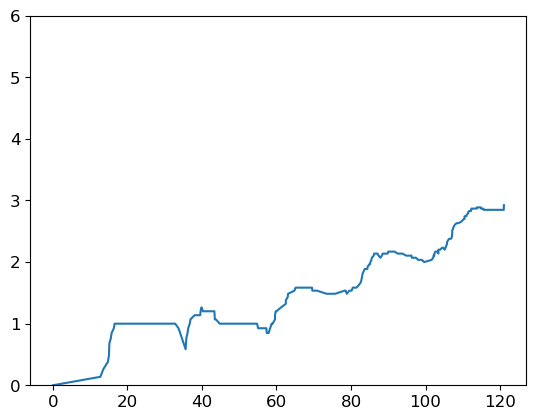

In [135]:
omega = 200
new_param = pd.read_csv("parameters.csv") 
del new_param['Stress']
for key in new_param.keys():
    if model_population.parameters[key].value != new_param[key][0]:
        model_population.parameters[key].value = int(round(new_param[key]* 200))
    if model_concentration.parameters[key].value != new_param[key][0]:
        model_concentration.parameters[key].value = new_param[key]
model_concentration.parameters['omega'].value = 1

model_population.parameters['ERK'].value = 0.2 * omega
model_population.parameters['FAK'].value = 0.4 * omega
model_population.parameters['AKT'].value = 0.3 * omega

model_concentration.parameters['ERK'].value = 0.2 * 1
model_concentration.parameters['FAK'].value = 1 * 1
model_concentration.parameters['AKT'].value = 0.6 * 1

conc = list(np.linspace(0,1,num=11))
conc = [round(x,1) for x in conc]
drug = 'cycD_low'
cycD_DIP_low = []
ii=0

for num in conc:
    figname = f"C:\\Users\\olesk\\ECM_mod_output\\{drug}_{str(ii)}.svg"
    model_population.parameters['CycDi_0'].value = num
    model_concentration.parameters['CycDi_0'].value = num
    tmp_m = run_model_DIP(nber_of_starting_cells, run_time, observed_cells_time, model_concentration, model_population, index, condition, figname)
    cycD_DIP_low.append(tmp_m)
    ii+=1

In [136]:
model_population.parameters['CycDi_0'].value

1.0